# KMOS — Multi-band galaxies: emission-line SNR in common Re-scaled annuli

Same data and pipeline as `kmos_snr_annuli_reff.ipynb` (cells 1–6 are identical),
but every galaxy that was observed in **more than one band** is shown in **one
figure**: e.g. Hα from the YJ cube and [OIII]5007 / Hβ from the IZ cube of the
same galaxy, side by side in the same radial profile.

**Common annuli.**  To compare lines from different cubes, all bands of a galaxy
use the **same Re** (one Re per galaxy, in arcsec → same physical rings):

* Re is taken from the band that covers **Hα** (the deeper one if Hα falls in two
  bands); if no band covers Hα, from the band with the highest central SNR.
* Each band keeps its **own centre** (line peak of that cube) — the cubes are
  separate pointings and need not share pixel coordinates.

Colour = emission line, hatching = band (legend: "Hα · YJ", "[OIII]5007 · IZ").

**Sections**
1–6. Imports, helpers, load + stack (one stack per galaxy and band), Re, annuli
7. Group galaxies with >1 band; common-Re annular SNR for every line × band
8. Gallery — one row per galaxy (image per band + joint SNR profile)
9. Detail view — joint profile + per-annulus spectra for every line × band

In [1]:
import glob, os, csv, pathlib, warnings, re
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from astropy.io import fits
from astropy.cosmology import FlatLambdaCDM

_COSMO = FlatLambdaCDM(H0=70, Om0=0.3)

def kpc_per_arcsec(z):
    """Proper kpc per arcsec at redshift z."""
    return float(_COSMO.kpc_proper_per_arcmin(z).to('kpc/arcsec').value)

# ── DATA SOURCE SWITCH ────────────────────────────────────────────────────────
USE_EXTERNAL = True           # True  → use kmos_proc_and_comb_server/ (combined cubes)
                              # False → use kmos_ob_proc_server/        (own reduced files)
COMB_BASE    = "kmos_proc_and_comb_server"

# ── paths ──────────────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server"
SUFFIX       = "_s_i_bkg2d_rv.fits"
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"

# ── extraction parameters ──────────────────────────────────────────────────────
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0   # px — beyond this, fall back to geometric centre
SPAXEL_SCALE      = 0.2   # arcsec / spaxel (KMOS plate scale)

# ── Hα SNR metric ──────────────────────────────────────────────────────────────
HA_REST      = 0.65628   # µm
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 3.0       # minimum central SNR to include in plots

# ── Emission lines ─────────────────────────────────────────────────────────────
# (label, rest_wavelength_µm, bar_color, snr_win_half_µm)
EMISSION_LINES = [
    ("Hα",          0.65628, "#d62728", 0.0025),
    ("[OIII]5007",  0.50073, "#1f77b4", 0.0020),
    ("[OIII]4959",  0.49598, "#9ecae1", 0.0015),
    ("Hβ",          0.48613, "#2ca02c", 0.0020),
]
LINE_COLORS = {lbl: lc for lbl, _, lc, _ in EMISSION_LINES}

# ── Re-scaled annuli ───────────────────────────────────────────────────────────
# Edges in units of Re (half-light radius measured from Hα image).
# Actual pixel edges are computed per galaxy as: edge_px = Re_px * REFF_EDGE
REFF_EDGES  = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]   # 5 annular shells
MIN_REFF_PX = 1.0    # minimum Re in spaxels to be usable; smaller → skip galaxy

# ── display ────────────────────────────────────────────────────────────────────
TOP_DETAIL = 20
ZOOM_HALF  = 0.018   # ±µm around primary line in spectra panels

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
]

ANNULUS_COLORS = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4", "#9467bd"]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── robust line S/N: scripts/line_snr.py ─────────────────────────────────────
import sys, importlib, pathlib
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr
importlib.reload(_lsnr)
import kmos_sample as ks          # galaxy identity, z lookup, exposure time, stacking
importlib.reload(ks)
canonical_field = ks.canonical_field

# ── data helpers ───────────────────────────────────────────────────────────────
def wavelength_axis(hdr):
    cdelt = hdr.get("CDELT3", hdr.get("CD3_3", 1.0))
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * cdelt + hdr["CRVAL3"]

def active_ifus(hdul):
    result = []
    for i in range(1, 25):
        try:
            d = hdul[i].data
            if d is not None and np.ndim(d) == 3:
                result.append(i)
        except Exception:
            pass
    return result

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def _aperture_spectrum_from_cube(cube, center, box=5, margin=EDGE_MARGIN):
    py, px = center
    h2 = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch   = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid   = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def aperture_spectrum(hdul, ifu, center, box=5, margin=EDGE_MARGIN):
    cube = np.array(hdul[ifu].data)
    wave = wavelength_axis(hdul[ifu].header)
    return wave, _aperture_spectrum_from_cube(cube, center, box, margin)

def annular_spectrum(cube, center, r_in, r_out, margin=EDGE_MARGIN):
    """Sum spectrum of spaxels with r_in <= dist(centre) < r_out."""
    nz, ny, nx = cube.shape
    cy, cx = center
    yy, xx = np.mgrid[0:ny, 0:nx]
    dist2  = (yy - cy)**2 + (xx - cx)**2
    ring   = (dist2 >= r_in**2) & (dist2 < r_out**2)
    idx    = np.where(ring)
    if len(idx[0]) == 0:
        return np.full(nz, np.nan)
    patch   = cube[:, idx[0], idx[1]]
    valid   = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(nz, np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def reff_from_image(image, center, margin=EDGE_MARGIN):
    """Estimate the Hα half-light radius (spaxels) via curve of growth.

    Returns the radius enclosing 50 % of the total positive flux in the
    (eroded) narrow-band image.  Returns nan if the image is unusable.
    """
    if image is None or not np.isfinite(image).any():
        return np.nan
    ny, nx = image.shape
    cy, cx = center

    valid  = _erode_valid(np.isfinite(image), margin)
    im_c   = np.where(valid, image, np.nan)

    yy, xx = np.mgrid[0:ny, 0:nx]
    dist   = np.hypot(yy - cy, xx - cx)
    r_max  = min(cy, cx, ny - cy - 1, nx - cx - 1)  # stay within IFU
    if r_max < 1:
        return np.nan

    # Fine radial steps
    r_steps  = np.linspace(0.0, float(r_max), int(r_max * 10) + 2)
    cum_flux = np.array([
        np.nansum(np.where(dist <= r, im_c, 0.0))
        for r in r_steps
    ])

    total = cum_flux[-1]
    if not np.isfinite(total) or total <= 0:
        return np.nan

    half = 0.5 * total
    idx  = np.searchsorted(cum_flux, half)
    if idx == 0:
        return float(r_steps[0])
    if idx >= len(r_steps):
        return float(r_steps[-1])

    # Linear interpolation between bracketing steps
    f0, f1 = cum_flux[idx - 1], cum_flux[idx]
    r0, r1 = r_steps[idx - 1], r_steps[idx]
    if f1 == f0:
        return float(r0)
    return float(r0 + (half - f0) / (f1 - f0) * (r1 - r0))

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

def ob_to_dpid(ob_name):
    if 'T' not in ob_name:
        return ob_name
    date_part, time_part = ob_name.split('T', 1)
    parts = time_part.split('-', 2)
    if len(parts) == 3:
        return f"{date_part}T{parts[0]}:{parts[1]}:{parts[2]}"
    return ob_name

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08, line_rest=HA_REST):
    ha_obs = line_rest * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat   = ha_im.ravel()
    order  = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im

def line_snr(wave, spec, z, line_rest=HA_REST,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
             min_width_px=3):
    """Robust S/N via scripts/line_snr.py: Gaussian-fit line flux / error
    (spikes masked, LSF/velocity priors, correlated noise; see that file)."""
    return _lsnr.line_snr(wave, spec, z, line_rest, win_half=win_half,
                          cont_in=cont_in, cont_out=cont_out)

# ── redshift catalogue ─────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                try:
                    _Z_QUALITY[_key] = float(_q)
                except (ValueError, TypeError):
                    _Z_QUALITY[_key] = np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts")
else:
    print(f"WARNING: {_Z_CSV} not found")

# galaxy-level redshift lookup: exact (target list, id), else (survey region, id)
# — e.g. 'SPT2040_Halpha' is not in the CSV but its galaxies are.  scripts/kmos_sample.py
ZCAT = ks.RedshiftCatalog(_Z_CSV)
z_lookup = ZCAT.lookup
print(f"  → {len(ZCAT)} unique galaxies (survey region, target id) with a redshift")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    zi = z_lookup(field, tid)
    return zi if zi is not None else (None, "", np.nan)

Loaded 178 redshifts
  → 158 unique galaxies (survey region, target id) with a redshift


In [3]:
# ── Load FITS catalog tables → group_id lookup ─────────────────────────────────
dpid_ifu_to_group = {}

for tbl_path in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl_path.exists():
        print(f"WARNING: {tbl_path} not found")
        continue
    with fits.open(tbl_path) as hdul:
        t = hdul[1].data
        for i in range(len(t)):
            dpid_ifu_to_group[(t['dp_id'][i].strip(), int(t['ifu'][i]))] = int(t['group_id'][i])
    print(f"Loaded {len(t):,} rows from {tbl_path.name}")

# Synthetic group_ids for fields not covered by the FITS tables
_synthetic_next = 90000
_field_tid_to_group = {}

for path in sorted(glob.glob(os.path.join(BASE, "*", "science", f"*{SUFFIX}"))):
    parts = path.replace("\\", "/").split("/")
    ob    = parts[-3]
    dpid  = ob_to_dpid(ob)
    with fits.open(path) as h:
        hdr0  = h[0].header
        field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
        if not field:
            continue
        for ifu in range(1, 25):
            if (dpid, ifu) in dpid_ifu_to_group:
                continue
            if ifu >= len(h):
                continue
            try:
                d = h[ifu].data
                if d is None or np.ndim(d) != 3:
                    continue
            except Exception:
                continue
            key_hdr = f"ESO OCS ARM{ifu} NAME"
            tid = str(hdr0.get(key_hdr) or hdr0.get(f"HIERARCH {key_hdr}") or "").strip()
            if not tid:
                continue
            k = (field, tid)
            if k not in _Z_TABLE:
                continue
            if k not in _field_tid_to_group:
                _field_tid_to_group[k] = _synthetic_next
                _synthetic_next += 1
            dpid_ifu_to_group[(dpid, ifu)] = _field_tid_to_group[k]

print(f"Total catalog entries (incl. {len(_field_tid_to_group)} synthetic): {len(dpid_ifu_to_group):,}")

Loaded 147,261 rows from table_ifus_ECDFS 2.fits


Loaded 119,729 rows from table_ifus_COSMOS_Field_exptime.fits
Total catalog entries (incl. 0 synthetic): 266,990


In [4]:
# ── Load all IFUs; stack individual cubes by group_id ──────────────────────────
print("Scanning exposures …")

def _read_dit(hdr):
    for key in ('HIERARCH ESO DET SEQ1 DIT', 'HIERARCH ESO DET SEQ1 REALDIT',
                'HIERARCH ESO DET DIT', 'EXPTIME'):
        v = hdr.get(key)
        if v is not None and float(v) > 0:
            return float(v)
    return 300.0

group_data = defaultdict(lambda: dict(
    cubes=[], obs=set(), wave=None,
    z=None, z_type='', z_quality=np.nan,
    ha_image=None, ctr_ha=None, ctr_geom=None, fallback=False,
    _best_snr=-np.inf,
    total_dit=0.0,
))

def _parse_field_tid(stem):
    parts = stem.split('_')
    for i in range(len(parts) - 1, 0, -1):
        f = '_'.join(parts[:i])
        t = '_'.join(parts[i:])
        if (f, t) in _Z_TABLE:
            return f, t
    p = stem.rsplit('_', 1)
    return (p[0], p[1]) if len(p) == 2 else (stem, '')

if USE_EXTERNAL:
    # ── combined cubes → one stack per (galaxy, band); see scripts/kmos_sample.py
    #    galaxy = (survey region, target id) across all target lists; z looked up
    #    per galaxy; on-source time = NCOMBINE × DIT (EXPTIME is 1.5× too short);
    #    cubes of one galaxy+band aligned on the sky and stacked by exposure time
    _stacks = ks.load_galaxy_band_stacks(COMB_BASE, ZCAT)
    for _st in _stacks:
        g = group_data[(_st['gid'], _st['band'])]
        g.update(wave=_st['wave'], z=_st['z'], z_type=_st['z_type'],
                 z_quality=_st['z_quality'], total_dit=_st['exptime_s'],
                 field=_st['field'], tid=_st['tid'], n_cubes=_st['n_cubes'],
                 target_lists=_st['target_lists'])
        g['cubes'] = [_st['cube']]
        g['obs'] = set(_st['folders'])
    _gid_to_field = {_st['gid']: _st['field'] for _st in _stacks}

else:
    exposures  = find_exposures()
    n_matched  = 0
    n_skipped  = 0

    for (ob, band), paths in sorted(exposures.items()):
        dpid = ob_to_dpid(ob)

        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            group_id = dpid_ifu_to_group.get((dpid, ifu))
            if group_id is None:
                n_skipped += 1
                continue
            n_matched += 1
            key = (group_id, band)
            g   = group_data[key]

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data, dtype=np.float32)
                    if g['wave'] is None:
                        g['wave'] = wavelength_axis(h[ifu].header)
                    if g['z'] is None:
                        z, z_type, z_quality = get_z_meta(h, ifu)
                        if z is not None:
                            g.update(z=z, z_type=z_type, z_quality=z_quality)
                    g['total_dit'] += _read_dit(h[0].header)
                    ref = np.nanmedian(cube)
                    if np.isfinite(ref) and ref != 0:
                        cube = cube / ref
                    g['cubes'].append(cube)
            g['obs'].add(ob)

    print(f"  IFU×OB matched: {n_matched}  |  skipped (no catalog): {n_skipped}")
    print(f"  Unique (group_id, band) stacks: {len(group_data)}")

Scanning exposures …


kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


In [5]:
# ── Median-stack cubes; measure Hα Re; compute central SNR ────────────────────
print("Stacking cubes and measuring Re …")

all_stacked = []
n_no_reff   = 0

for (group_id, band), g in group_data.items():
    if not g['cubes'] or g['wave'] is None or g.get('z') is None:
        continue

    wave = g['wave']
    z    = g['z']

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stacked = np.nanmedian(np.stack(g['cubes'], axis=0), axis=0)

    ctr_geom      = ifu_center(stacked)
    med_spec_geom = _aperture_spectrum_from_cube(stacked, ctr_geom, box=5)

    # Which lines fall in this wavelength range?
    snr_by_line = {}
    for lbl, lrest, lcolor, lwh in EMISSION_LINES:
        lam_obs = lrest * (1.0 + z)
        if not (wave.min() < lam_obs < wave.max()):
            snr_by_line[lbl] = np.nan
        else:
            snr_by_line[lbl] = line_snr(wave, med_spec_geom, z, line_rest=lrest, win_half=lwh)

    # Use the highest-SNR line for centre-finding
    best_lrest = HA_REST
    best_snr_c = -np.inf
    for lbl, lrest, _, _ in EMISSION_LINES:
        s = snr_by_line.get(lbl, np.nan)
        if np.isfinite(s) and s > best_snr_c:
            best_snr_c = s
            best_lrest = lrest

    ctr_raw, line_image = ha_peak_center(stacked, wave, z, line_rest=best_lrest)
    offset   = np.hypot(ctr_raw[0] - ctr_geom[0], ctr_raw[1] - ctr_geom[1])
    fallback = offset > MAX_CENTER_OFFSET
    ctr_ha   = ctr_geom if fallback else ctr_raw

    # Recompute SNR with refined centre
    med_spec = _aperture_spectrum_from_cube(stacked, ctr_ha, box=5)
    for lbl, lrest, lcolor, lwh in EMISSION_LINES:
        lam_obs = lrest * (1.0 + z)
        if not (wave.min() < lam_obs < wave.max()):
            snr_by_line[lbl] = np.nan
        else:
            snr_by_line[lbl] = line_snr(wave, med_spec, z, line_rest=lrest, win_half=lwh)

    snr_central = max((v for v in snr_by_line.values() if np.isfinite(v)), default=np.nan)

    # ── Measure Hα effective radius (half-light radius) from the narrow-band image
    reff_px  = reff_from_image(line_image, ctr_ha)
    reff_arc = reff_px * SPAXEL_SCALE if np.isfinite(reff_px) else np.nan
    reff_kpc = reff_arc * kpc_per_arcsec(z) if np.isfinite(reff_arc) else np.nan

    if np.isfinite(reff_px) and reff_px >= MIN_REFF_PX:
        reff_usable = True
    else:
        reff_usable = False
        n_no_reff  += 1

    all_stacked.append(dict(
        group_id        = group_id,
        field           = g.get('field', '?'),
        tid             = str(g.get('tid', '')),
        band            = band,
        z               = z,
        z_type          = g['z_type'],
        z_quality       = g['z_quality'],
        wave            = wave,
        cube            = stacked,
        ha_image        = line_image,
        ctr_ha          = ctr_ha,
        ctr_geom        = ctr_geom,
        fallback        = fallback,
        n_obs           = len(g['obs']),
        n_exp           = g.get('n_cubes', len(g['cubes'])),
        total_exptime_s = g['total_dit'],
        snr_central     = snr_central,
        snr_by_line     = snr_by_line,
        med_spec        = med_spec,
        reff_px         = reff_px,      # spaxels
        reff_arc        = reff_arc,     # arcsec
        reff_kpc        = reff_kpc,     # kpc (proper)
        reff_usable     = reff_usable,  # Re >= MIN_REFF_PX
        kpc_per_arcsec  = kpc_per_arcsec(z),
    ))

all_stacked.sort(
    key=lambda x: x['snr_central'] if np.isfinite(x.get('snr_central', np.nan)) else -np.inf,
    reverse=True,
)

detected = all_stacked   # keep all; filtering happens in gallery/detail

def _texp_str(t_s):
    return f"{t_s/3600:.1f} h"

_re_arc_hdr = "Re(arc)"
print(f"(galaxy, band) stacks: {len(all_stacked)}  (unique galaxies: {len({e['group_id'] for e in all_stacked})})  "
      f"(Re usable: {len(all_stacked)-n_no_reff},  "
      f"Re < {MIN_REFF_PX:.1f} px: {n_no_reff})")
print()
print(f"{'#':>3}  {'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'type':>7}  "
      f"{'N_obs':>5}  {'T_exp':>7}  {'Re(px)':>7}  {_re_arc_hdr:>7}  {'Re(kpc)':>8}  "
      f"{'Ha SNR':>7}  {'[OIII] SNR':>10}  {'Hb SNR':>7}")
print("-" * 100)
for i, e in enumerate(detected):
    sbl = e['snr_by_line']
    def _s(v): return f"{v:.1f}" if np.isfinite(v) else "-"
    re_s  = f"{e['reff_px']:.2f}" if np.isfinite(e['reff_px']) else "-"
    rea_s = f"{e['reff_arc']:.2f}" if np.isfinite(e['reff_arc']) else "-"
    rek_s = f"{e['reff_kpc']:.2f}" if np.isfinite(e['reff_kpc']) else "-"
    fb    = '*' if e.get('fallback') else ' '
    print(f"{i+1:>3}  {e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  "
          f"{e['z_type']:>7}  {e['n_obs']:>5}  "
          f"{_texp_str(e['total_exptime_s']):>7}  "
          f"{re_s:>7}  {rea_s:>7}  {rek_s:>8}  "
          f"{_s(sbl.get('Ha', sbl.get('Halpha', sbl.get('Hα', np.nan)))):>7}  "
          f"{_s(sbl.get('[OIII]5007', np.nan)):>10}  "
          f"{_s(sbl.get('Hb', sbl.get('Hbeta', sbl.get('Hβ', np.nan)))):>7}{fb}")

Stacking cubes and measuring Re …


(galaxy, band) stacks: 253  (unique galaxies: 158)  (Re usable: 196,  Re < 1.0 px: 57)

  #     gid  field         tid  band         z     type  N_obs    T_exp   Re(px)  Re(arc)   Re(kpc)   Ha SNR  [OIII] SNR   Hb SNR
----------------------------------------------------------------------------------------------------
  1   90107  COSMOS      97505  YJ      0.6613     spec      1    4.8 h     2.98     0.60      4.16     76.4           -        - 
  2   90097  COSMOS      92754  YJ      0.6263     spec      1    4.8 h     3.21     0.64      4.37     72.7           -        - 
  3   90091  COSMOS      90874  YJ      0.6629     spec      1    4.8 h     2.81     0.56      3.92     44.2           -        - 
  4   90020  CDFS        23420  IZ      0.6050     spec      1   10.7 h     3.19     0.64      4.28     39.2        13.1        - 
  5   90053  COSMOS    1168518  YJ      0.7368     spec      1    2.9 h     2.22     0.44      3.24     37.1           -        - 
  6   90145  XMM2215     3

In [6]:
# ── Compute SNR in each Re-scaled annular shell ────────────────────────────────
n_ann = len(REFF_EDGES) - 1

for e in detected:
    cube  = e['cube']
    wave  = e['wave']
    z     = e['z']
    ctr   = e['ctr_ha']
    reff  = e['reff_px']   # spaxels; may be nan

    if not e['reff_usable']:
        # Store empty results so downstream code doesn't crash
        e['ann_specs']        = [np.full(len(wave), np.nan)] * n_ann
        e['ann_snrs_by_line'] = {lbl: [np.nan]*n_ann for lbl, *_ in EMISSION_LINES}
        e['ann_snrs']         = [np.nan] * n_ann
        e['ann_edges_px']     = [np.nan] * (n_ann + 1)
        e['ann_edges_arc']    = [np.nan] * (n_ann + 1)
        e['ann_edges_kpc']    = [np.nan] * (n_ann + 1)
        continue

    # Per-galaxy pixel edges for the annuli
    edges_px  = [r * reff for r in REFF_EDGES]
    edges_arc = [r * e['reff_arc'] for r in REFF_EDGES]
    edges_kpc = [r * e['reff_kpc'] for r in REFF_EDGES]

    e['ann_edges_px']  = edges_px
    e['ann_edges_arc'] = edges_arc
    e['ann_edges_kpc'] = edges_kpc

    ann_specs        = []
    ann_snrs_by_line = {lbl: [] for lbl, *_ in EMISSION_LINES}

    for i in range(n_ann):
        spec = annular_spectrum(cube, ctr, edges_px[i], edges_px[i+1])
        ref  = np.nanmedian(spec)
        if np.isfinite(ref) and ref != 0:
            spec = spec / ref
        ann_specs.append(spec)
        for lbl, lrest, lcolor, lwh in EMISSION_LINES:
            lam_obs = lrest * (1.0 + z)
            if not (wave.min() < lam_obs < wave.max()):
                ann_snrs_by_line[lbl].append(np.nan)
            else:
                ann_snrs_by_line[lbl].append(
                    line_snr(wave, spec, z, line_rest=lrest, win_half=lwh))

    e['ann_specs']        = ann_specs
    e['ann_snrs_by_line'] = ann_snrs_by_line
    e['ann_snrs']         = ann_snrs_by_line.get("Hα", [np.nan]*n_ann)

usable = [e for e in detected if e['reff_usable']]
print(f"Re-scaled annular SNR profiles computed for {len(usable)} galaxies "
      f"(skipped {len(detected)-len(usable)} with Re < {MIN_REFF_PX} px).")
print()

# Print per-galaxy summary
for lbl, *_ in EMISSION_LINES:
    rows = [e for e in usable
            if any(np.isfinite(v) for v in e['ann_snrs_by_line'].get(lbl, []))]
    if not rows:
        continue
    ann_hdr = "  ".join(
        f"{REFF_EDGES[i]:.1f}–{REFF_EDGES[i+1]:.1f}Re" for i in range(n_ann))
    print(f"── {lbl} ──")
    print(f"{'gid':>6}  {'z':>7}  {'Re(px)':>7}  {'Re(kpc)':>8}  {ann_hdr}")
    print("-" * (40 + 12 * n_ann))
    for e in rows:
        snrs = e['ann_snrs_by_line'][lbl]
        re_s = f"{e['reff_px']:.2f}" if np.isfinite(e['reff_px']) else "—"
        rek_s = f"{e['reff_kpc']:.2f}" if np.isfinite(e['reff_kpc']) else "—"
        row  = f"{e['group_id']:>6}  {e['z']:>7.4f}  {re_s:>7}  {rek_s:>8}  "
        row += "  ".join(
            f"{v:>9.1f}" if np.isfinite(v) else f"{'—':>9}" for v in snrs)
        print(row)
    print()

C:\Users\kreuter\AppData\Local\Temp\ipykernel_27936\97294130.py:35: RuntimeWarning: All-NaN slice encountered
  ref  = np.nanmedian(spec)


Re-scaled annular SNR profiles computed for 196 galaxies (skipped 57 with Re < 1.0 px).

── Hα ──
   gid        z   Re(px)   Re(kpc)  0.0–0.5Re  0.5–1.0Re  1.0–1.5Re  1.5–2.0Re  2.0–3.0Re
----------------------------------------------------------------------------------------------------
 90107   0.6613     2.98      4.16       69.0       77.1       43.7       17.0        0.7
 90097   0.6263     3.21      4.37       80.9       57.2       26.5       11.7        3.8
 90091   0.6629     2.81      3.92       28.8       48.6       28.3       16.3        5.4
 90020   0.6050     3.19      4.28       40.4       27.6        8.6        3.1        1.0
 90053   0.7368     2.22      3.24       50.0       33.9       16.2        6.5       -0.1
 90145   1.4502     6.12     10.35       29.7        1.9       -0.8        1.5          —
 90150   1.4540     2.21      3.74       37.8       19.1       12.5        7.7        2.0
 90151   1.4610     2.22      3.75       17.5       19.8       19.7        6.0   

## Group multi-band galaxies — common Re, joint annuli

In [7]:
# ── Group the (galaxy, band) stacks by galaxy; common Re; joint annuli ──────────
def _covers(e, lrest):
    return e['wave'].min() < lrest * (1.0 + e['z']) < e['wave'].max()

def _finite_or(v, default=-np.inf):
    return v if (v is not None and np.isfinite(v)) else default

BAND_HATCH = ['', '////', '....', 'xxxx']      # 1st, 2nd, 3rd band of a galaxy

_by_gal = defaultdict(list)
for e in detected:
    _by_gal[e['group_id']].append(e)

groups = []
for gid, ents in _by_gal.items():
    if len({e['band'] for e in ents}) < 2:
        continue                                   # single-band galaxy
    ents = sorted(ents, key=lambda e: ks.band_rank(e['band']))
    usable = [e for e in ents if e['reff_usable']]
    if not usable:
        continue                                   # no band gives a usable Re

    # reference band for Re: Hα band (deepest), else highest central SNR
    ha_bands = [e for e in usable if _covers(e, HA_REST)]
    ref = (max(ha_bands, key=lambda e: e['total_exptime_s']) if ha_bands
           else max(usable, key=lambda e: _finite_or(e['snr_central'])))
    reff_px, reff_arc, reff_kpc = ref['reff_px'], ref['reff_arc'], ref['reff_kpc']
    edges_px  = [r * reff_px  for r in REFF_EDGES]
    edges_arc = [r * reff_arc for r in REFF_EDGES]
    edges_kpc = [r * reff_kpc for r in REFF_EDGES]

    combos = []                                    # one per (line, band)
    for bi, e in enumerate(ents):
        specs = []
        for i in range(n_ann):
            spec = annular_spectrum(e['cube'], e['ctr_ha'], edges_px[i], edges_px[i + 1])
            ref_level = np.nanmedian(spec)
            if np.isfinite(ref_level) and ref_level != 0:
                spec = spec / ref_level
            specs.append(spec)
        for lbl, lrest, lcolor, lwh in EMISSION_LINES:
            if not _covers(e, lrest):
                continue
            snrs = [line_snr(e['wave'], s, e['z'], line_rest=lrest, win_half=lwh)
                    for s in specs]
            combos.append(dict(
                lbl=lbl, lrest=lrest, lcolor=lcolor, lwh=lwh,
                band=e['band'], hatch=BAND_HATCH[bi % len(BAND_HATCH)],
                entry=e, specs=specs, snrs=snrs,
                snr_central=e['snr_by_line'].get(lbl, np.nan),
            ))
    if not combos:
        continue

    groups.append(dict(
        group_id=gid, field=ents[0]['field'], tid=ents[0]['tid'],
        z=ents[0]['z'], z_type=ents[0]['z_type'],
        entries=ents, ref=ref,
        reff_px=reff_px, reff_arc=reff_arc, reff_kpc=reff_kpc,
        edges_px=edges_px, edges_arc=edges_arc, edges_kpc=edges_kpc,
        kpc_per_arcsec=ref['kpc_per_arcsec'],
        combos=combos,
        best_snr=max(_finite_or(c['snr_central']) for c in combos),
    ))

groups.sort(key=lambda g: g['best_snr'], reverse=True)

def _combo_label(c):
    return f"{c['lbl']} · {c['band']}"

n_multi = len({gid for gid, ents in _by_gal.items() if len({e['band'] for e in ents}) > 1})
print(f"Galaxies observed in >1 band: {n_multi}   "
      f"with a usable Re in at least one band: {len(groups)}")
for f in sorted({g['field'] for g in groups}):
    sub = [g for g in groups if g['field'] == f]
    bands = sorted({'+'.join(e['band'] for e in g['entries']) for g in sub})
    print(f"  {f:8s} {len(sub):3d} galaxies   bands: {', '.join(bands)}")
print()
print(f"{'#':>3}  {'field':8} {'tid':>8}  {'z':>7}  {'Re ref':>6}  {'Re(\")':>6}  {'Re(kpc)':>7}  "
      f"central SNR per line · band")
print("-" * 110)
for i, g in enumerate(groups):
    parts = "   ".join(f"{_combo_label(c)}={c['snr_central']:.1f}" if np.isfinite(c['snr_central'])
                       else f"{_combo_label(c)}=—" for c in g['combos'])
    print(f"{i+1:>3}  {g['field']:8} {g['tid']:>8}  {g['z']:>7.4f}  {g['ref']['band']:>6}  "
          f"{g['reff_arc']:>6.2f}  {g['reff_kpc']:>7.2f}  {parts}")

C:\Users\kreuter\AppData\Local\Temp\ipykernel_27936\515526882.py:37: RuntimeWarning: All-NaN slice encountered
  ref_level = np.nanmedian(spec)


Galaxies observed in >1 band: 95   with a usable Re in at least one band: 88
  COSMOS    47 galaxies   bands: IZ+YJ
  SPT2040   21 galaxies   bands: YJ+H
  XMM2215   20 galaxies   bands: YJ+H

  #  field         tid        z  Re ref   Re(")  Re(kpc)  central SNR per line · band
--------------------------------------------------------------------------------------------------------------
  1  COSMOS      97505   0.6613      YJ    0.60     4.16  [OIII]5007 · IZ=1.1   [OIII]4959 · IZ=1.4   Hβ · IZ=3.3   Hα · YJ=76.4
  2  COSMOS      92754   0.6263      IZ    0.60     4.11  Hα · IZ=25.1   [OIII]5007 · IZ=2.0   [OIII]4959 · IZ=1.7   Hβ · IZ=0.8   Hα · YJ=72.7
  3  COSMOS      90874   0.6629      YJ    0.56     3.92  [OIII]5007 · IZ=2.1   [OIII]4959 · IZ=1.9   Hβ · IZ=1.8   Hα · YJ=44.2
  4  COSMOS    1168518   0.7368      YJ    0.44     3.24  [OIII]5007 · IZ=0.9   [OIII]4959 · IZ=-4.3   Hβ · IZ=1.2   Hα · YJ=37.1
  5  XMM2215     31179   1.4502       H    1.22    10.35  [OIII]5007 · YJ=10.7

In [8]:
# ── Plot helpers shared by gallery and detail view ─────────────────────────────
def _draw_band_image(ax, g, e, title_fs=6.5):
    """Primary-line image of one band with the galaxy's common Re circles."""
    im = e.get('ha_image')
    cy, cx = e['ctr_ha']
    if im is not None and np.isfinite(im).any():
        fin = im[np.isfinite(im)]
        ax.imshow(im, origin='lower', aspect='equal', cmap='inferno',
                  vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
    else:
        ax.set_facecolor('#111')
    for i, r_px in enumerate(g['edges_px'][1:]):
        ax.add_patch(plt.Circle((cx, cy), r_px, fill=False,
                                edgecolor=ANNULUS_COLORS[i], lw=1.0, ls='--', alpha=0.85))
    ax.add_patch(plt.Circle((cx, cy), g['reff_px'], fill=False,
                            edgecolor='white', lw=1.5, ls='-', alpha=0.6))
    ax.plot(cx, cy, '+', ms=7, mew=1.5, color='white', zorder=5)
    fb = '  [fb]' if e.get('fallback') else ''
    ref_mark = '  (Re ref)' if e is g['ref'] else ''
    ax.set_title(f"{e['band']}{ref_mark}{fb}  ·  T={_texp_str(e['total_exptime_s'])}",
                 fontsize=title_fs, pad=3)
    ax.tick_params(labelsize=6)


def _draw_joint_profile(ax, g, annotate=False, legend=True, tick_fs=6):
    """Grouped SNR bars: colour = line, hatching = band."""
    combos = g['combos']
    n_c    = len(combos)
    bar_w  = 0.8 / max(n_c, 1)
    xs     = np.arange(n_ann)
    for ci, c in enumerate(combos):
        offset = (ci - (n_c - 1) / 2) * bar_w
        vals   = [v if np.isfinite(v) else 0 for v in c['snrs']]
        bars   = ax.bar(xs + offset, vals, bar_w * 0.9, color=c['lcolor'], alpha=0.85,
                        edgecolor='#333', lw=0.5, hatch=c['hatch'],
                        label=_combo_label(c), zorder=3)
        for bi, v in enumerate(c['snrs']):
            if not np.isfinite(v):
                bars[bi].set_hatch('//')
                bars[bi].set_edgecolor('#aaa')
                bars[bi].set_alpha(0.4)
            if annotate:
                txt  = f"{v:.1f}" if np.isfinite(v) else "—"
                ypos = (v + 0.3) if (np.isfinite(v) and v > 0) else 0.5
                ax.text(xs[bi] + offset, ypos, txt, ha='center', va='bottom',
                        fontsize=5.5, color=c['lcolor'] if np.isfinite(v) else '#aaa')
    ax.axhline(0, color='#555', lw=0.6)
    ax.axhline(SNR_MIN, color='k', lw=0.8, ls=':', alpha=0.5)
    ax.set_xticks(xs)
    ax.set_xticklabels([
        f"{REFF_EDGES[i]:.1f}–{REFF_EDGES[i+1]:.1f} Re\n"
        f"{g['edges_arc'][i]:.2f}–{g['edges_arc'][i+1]:.2f}\"\n"
        f"{g['edges_kpc'][i]:.1f}–{g['edges_kpc'][i+1]:.1f} kpc"
        for i in range(n_ann)], fontsize=tick_fs)
    ax.set_ylabel("SNR", fontsize=8)
    if legend:
        ax.legend(fontsize=6.5, loc='upper right', framealpha=0.7,
                  handlelength=1.6, handletextpad=0.4, ncol=1 + (n_c > 4))

## Gallery — one row per galaxy

Left: primary-line image of each band with the common Re circles (dashed = Re multiples, solid = 1 Re).  Right: SNR in each annulus for every line × band.

In [9]:
if not groups:
    print("No multi-band galaxies with usable Re.")
else:
    n      = len(groups)
    max_nb = max(len(g['entries']) for g in groups)
    fig    = plt.figure(figsize=(4.2 * max_nb + 8, n * 3.2), constrained_layout=True)
    outer  = gridspec.GridSpec(n, 1, figure=fig)
    fig.suptitle(
        f"KMOS multi-band galaxies — Emission-line SNR in common Re-scaled annuli  "
        f"({n} galaxies; colour = line, hatching = band)",
        fontsize=11, fontweight='bold', y=1.002,
    )
    for ri, g in enumerate(groups):
        inner = gridspec.GridSpecFromSubplotSpec(
            1, max_nb + 1, subplot_spec=outer[ri],
            width_ratios=[1] * max_nb + [2.6], wspace=0.25)
        for bi, e in enumerate(g['entries']):
            _draw_band_image(fig.add_subplot(inner[bi]), g, e)
        ax_snr = fig.add_subplot(inner[max_nb])
        _draw_joint_profile(ax_snr, g)
        ax_snr.set_title(
            f"{g['field']} {g['tid']}  ·  z={g['z']:.4f} [{g['z_type']}]  ·  "
            f"Re={g['reff_arc']:.2f}\"={g['reff_kpc']:.2f} kpc (from {g['ref']['band']})",
            fontsize=7.5, pad=3)

    plt.savefig("kmos_snr_reff_group_gallery.pdf", bbox_inches='tight')
    plt.show()
    print("Saved → kmos_snr_reff_group_gallery.pdf")

Saved → kmos_snr_reff_group_gallery.pdf


## Detail view — joint profile and per-annulus spectra

Top `TOP_DETAIL` galaxies by their best central SNR.  One spectrum row per line × band.

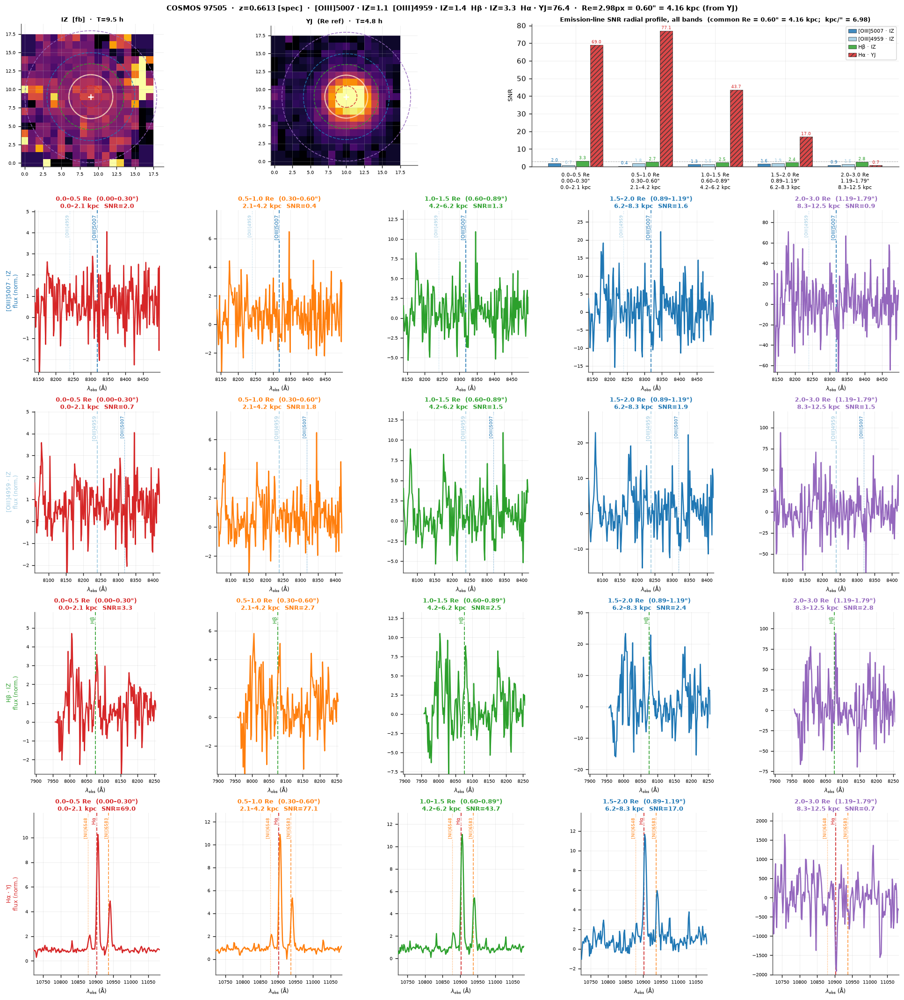

Saved → kmos_snr_reff_group_detail_COSMOS_97505.pdf


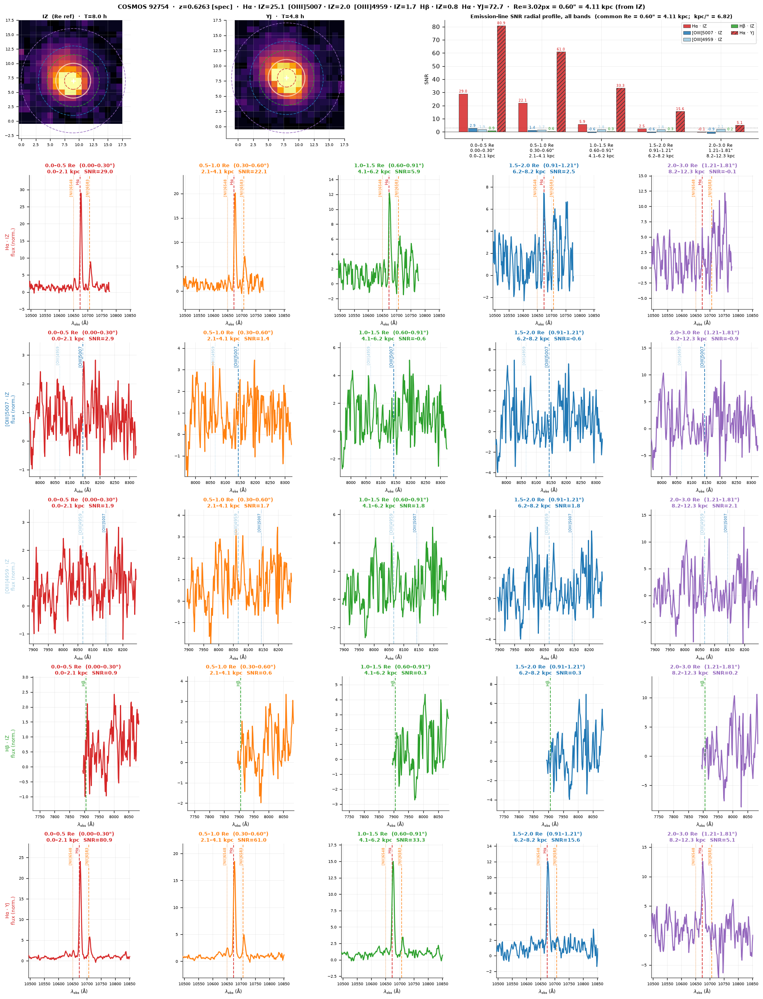

Saved → kmos_snr_reff_group_detail_COSMOS_92754.pdf


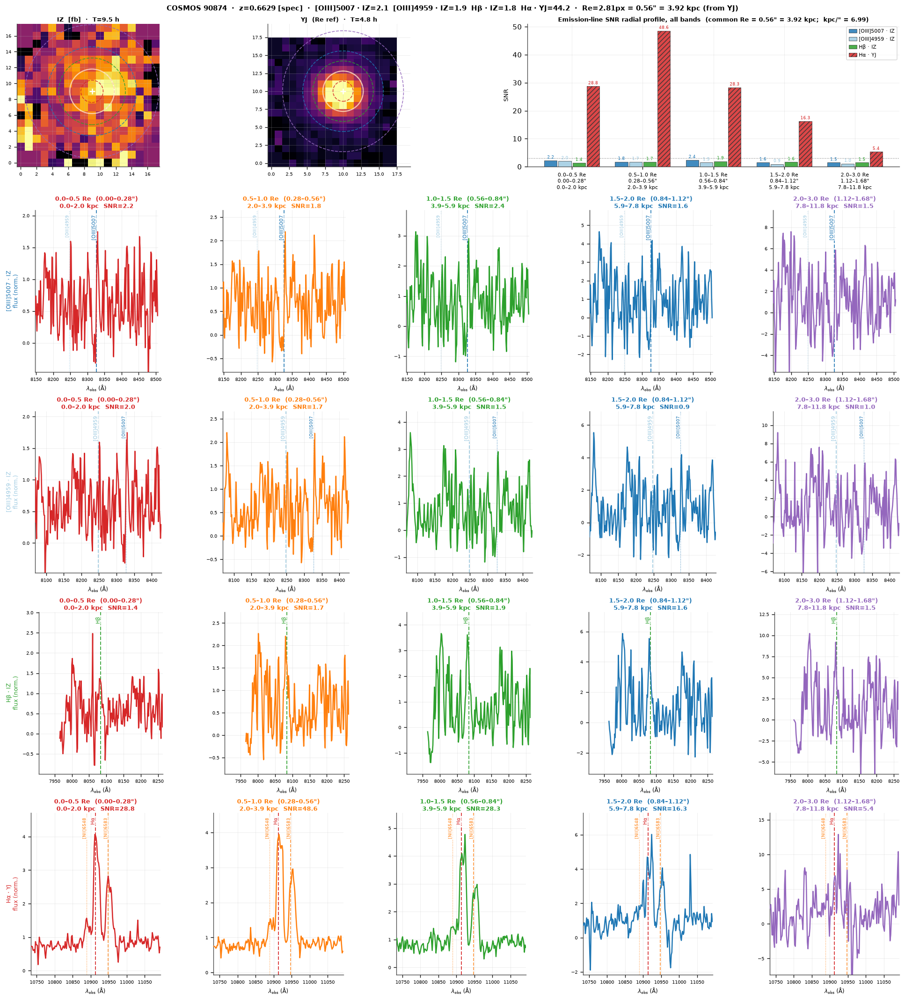

Saved → kmos_snr_reff_group_detail_COSMOS_90874.pdf


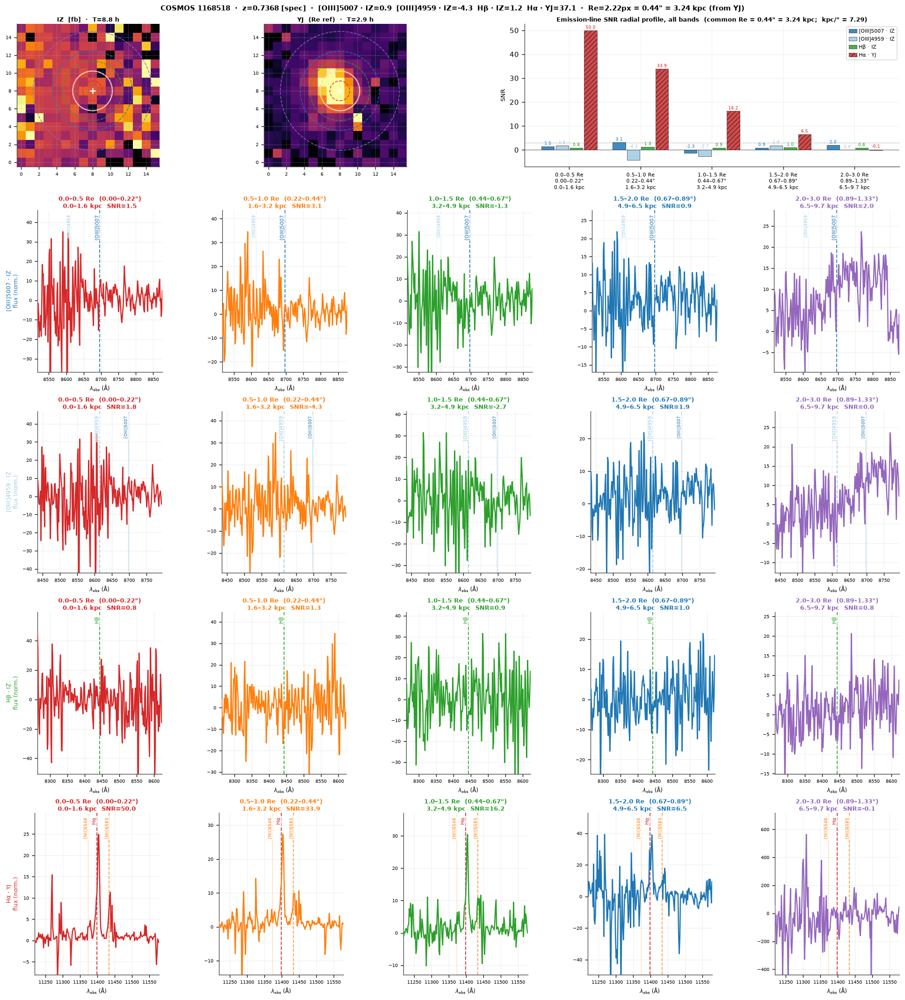

Saved → kmos_snr_reff_group_detail_COSMOS_1168518.pdf


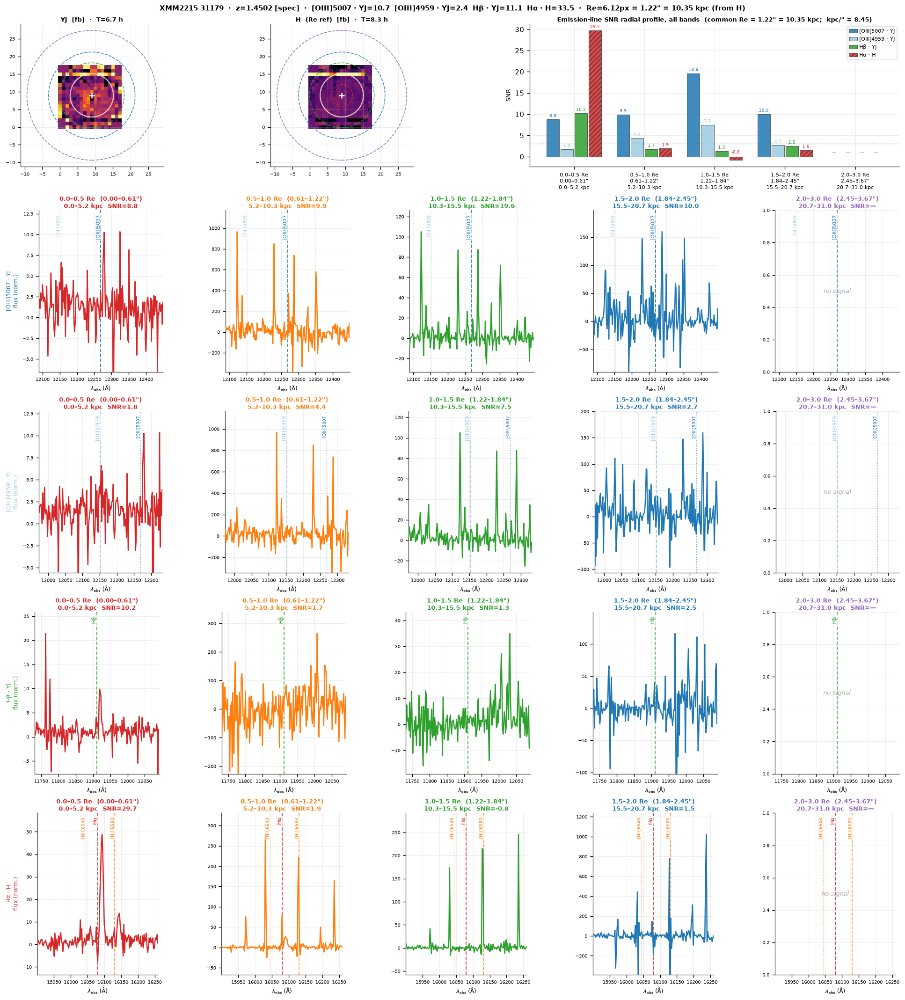

Saved → kmos_snr_reff_group_detail_XMM2215_31179.pdf


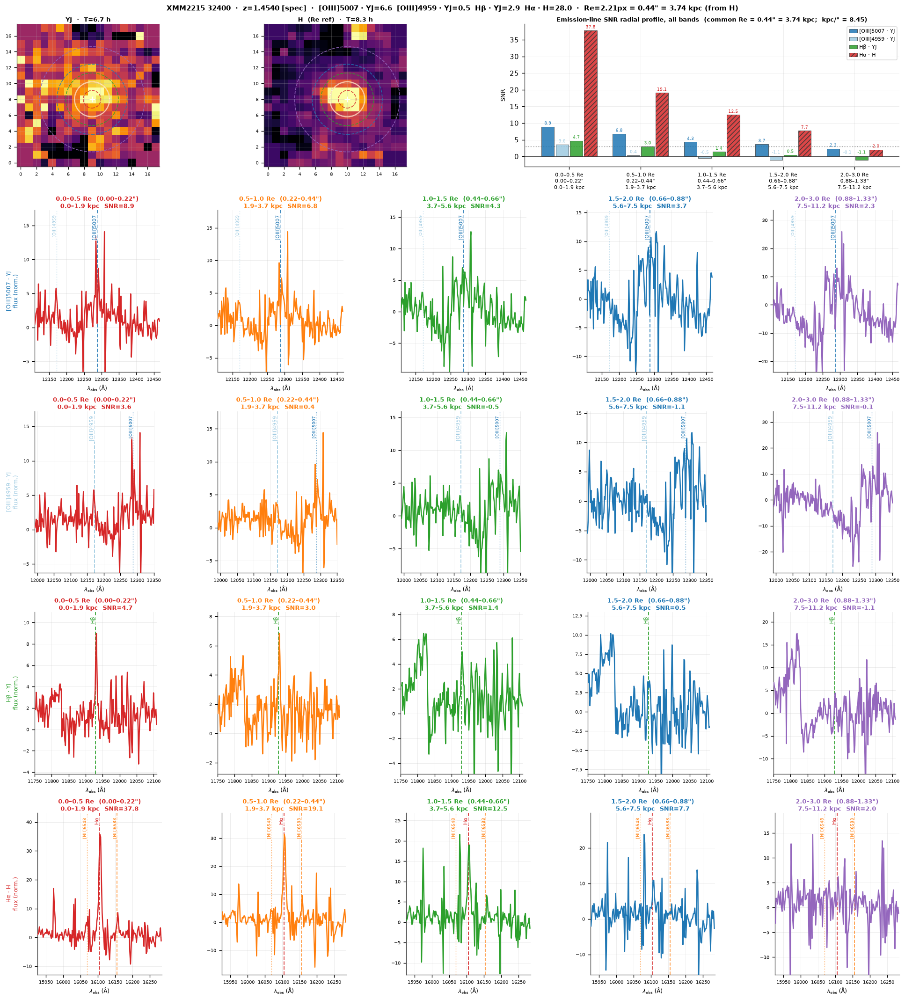

Saved → kmos_snr_reff_group_detail_XMM2215_32400.pdf


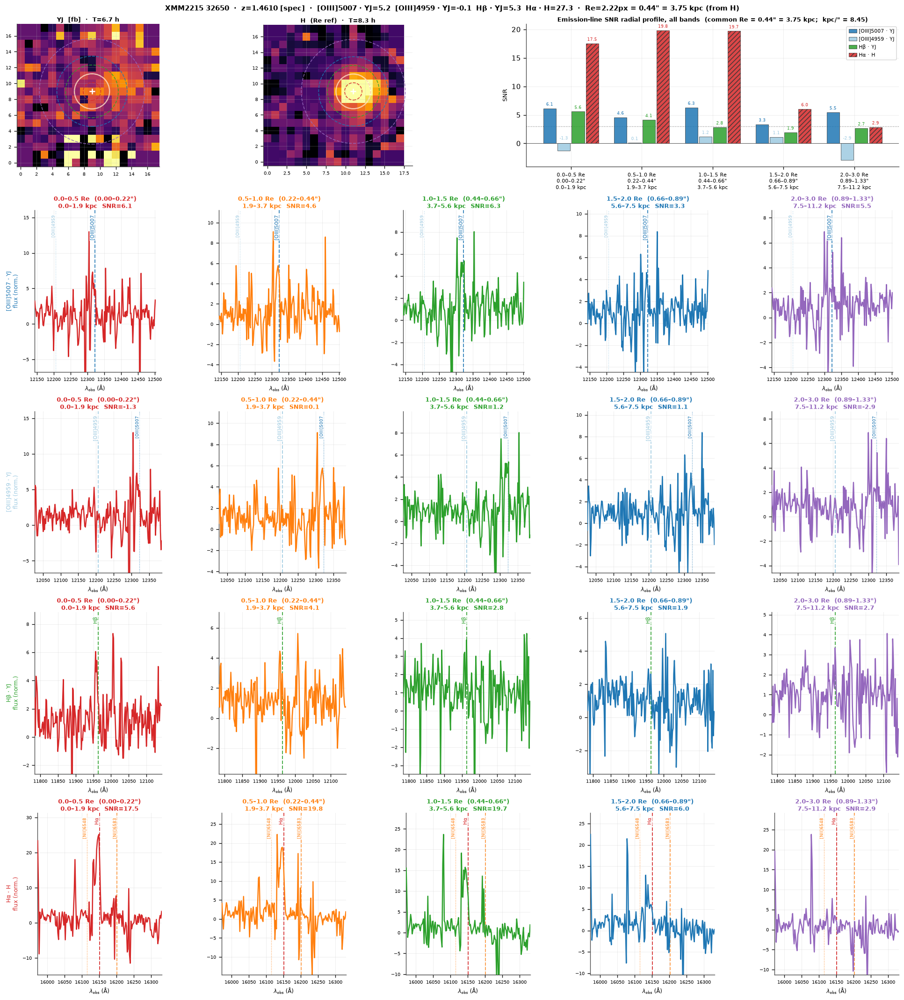

Saved → kmos_snr_reff_group_detail_XMM2215_32650.pdf


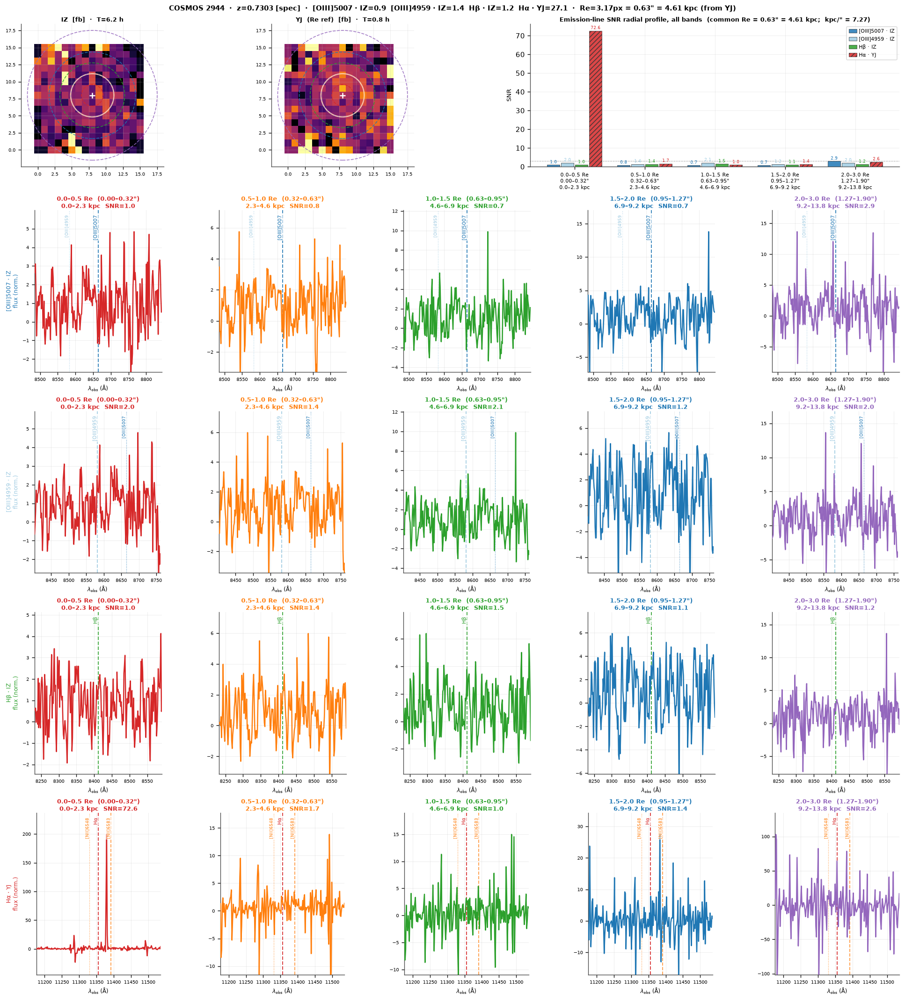

Saved → kmos_snr_reff_group_detail_COSMOS_2944.pdf


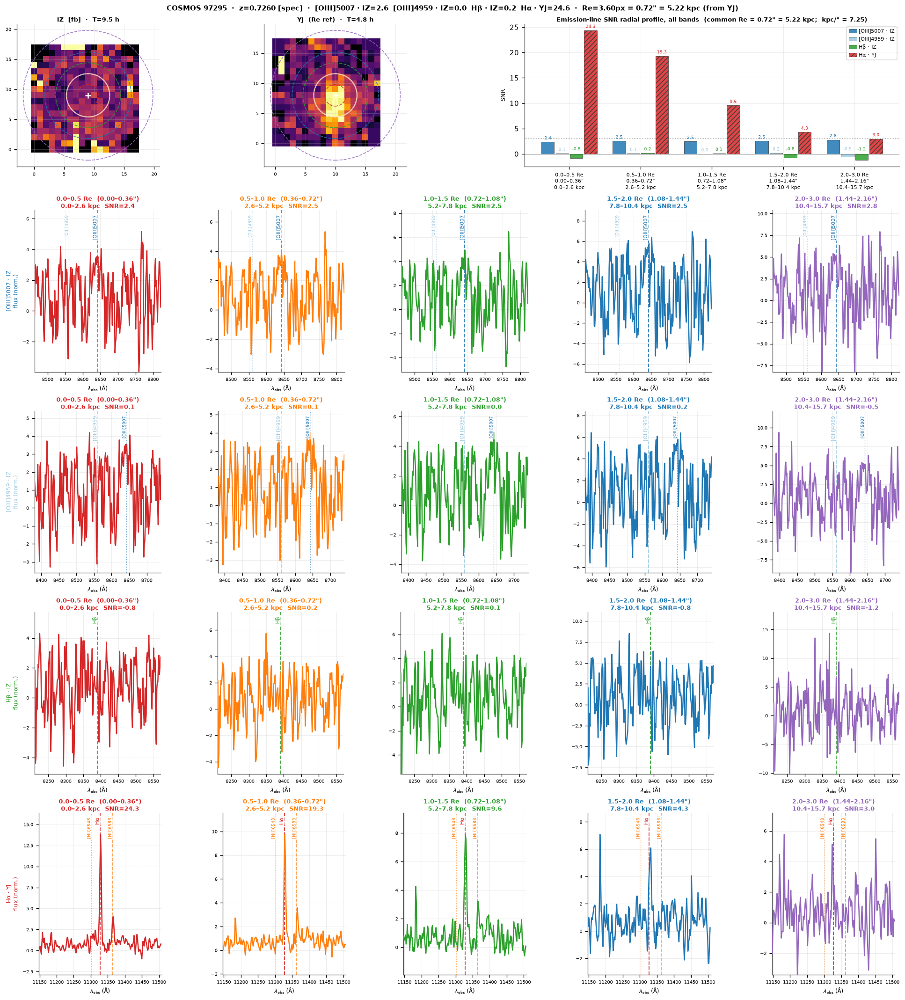

Saved → kmos_snr_reff_group_detail_COSMOS_97295.pdf


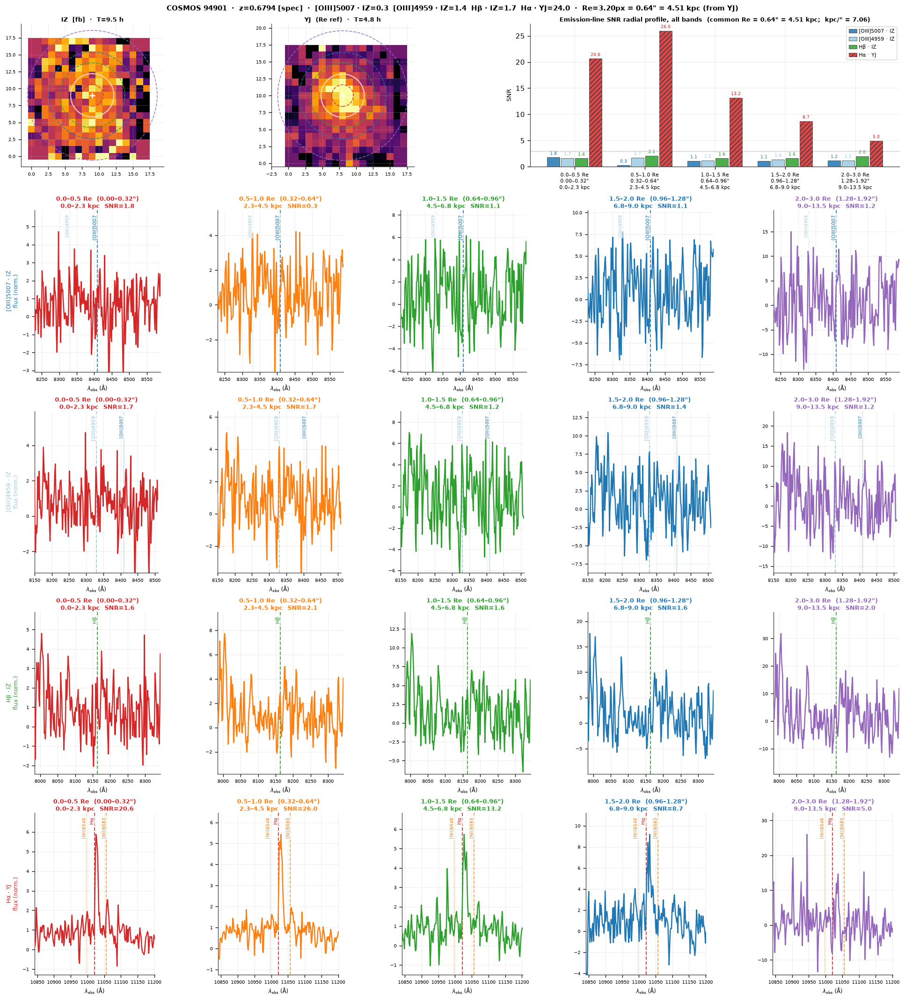

Saved → kmos_snr_reff_group_detail_COSMOS_94901.pdf


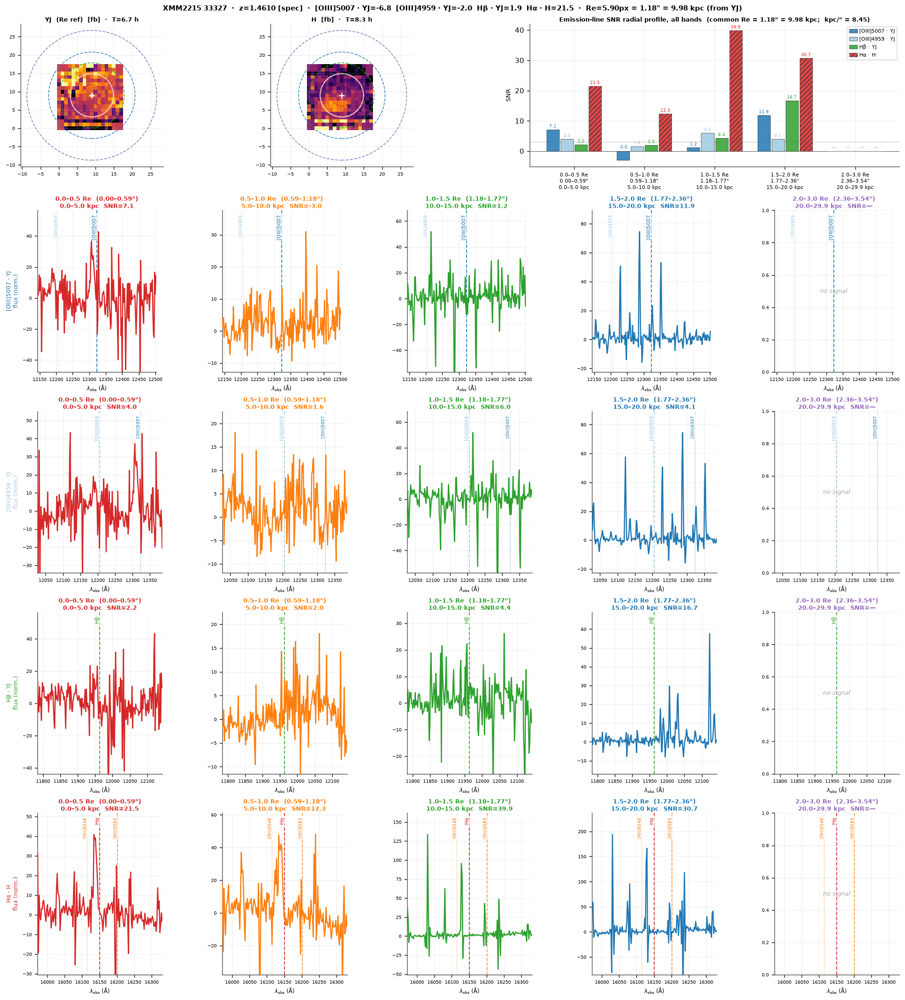

Saved → kmos_snr_reff_group_detail_XMM2215_33327.pdf


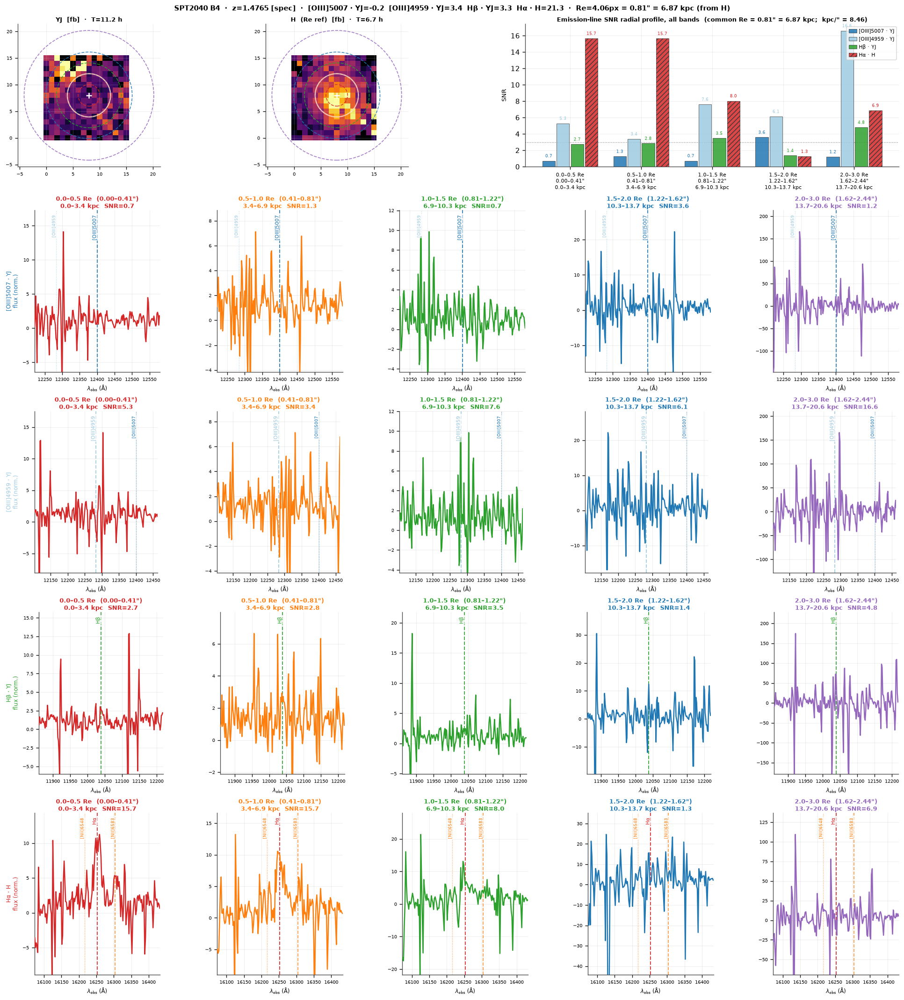

Saved → kmos_snr_reff_group_detail_SPT2040_B4.pdf


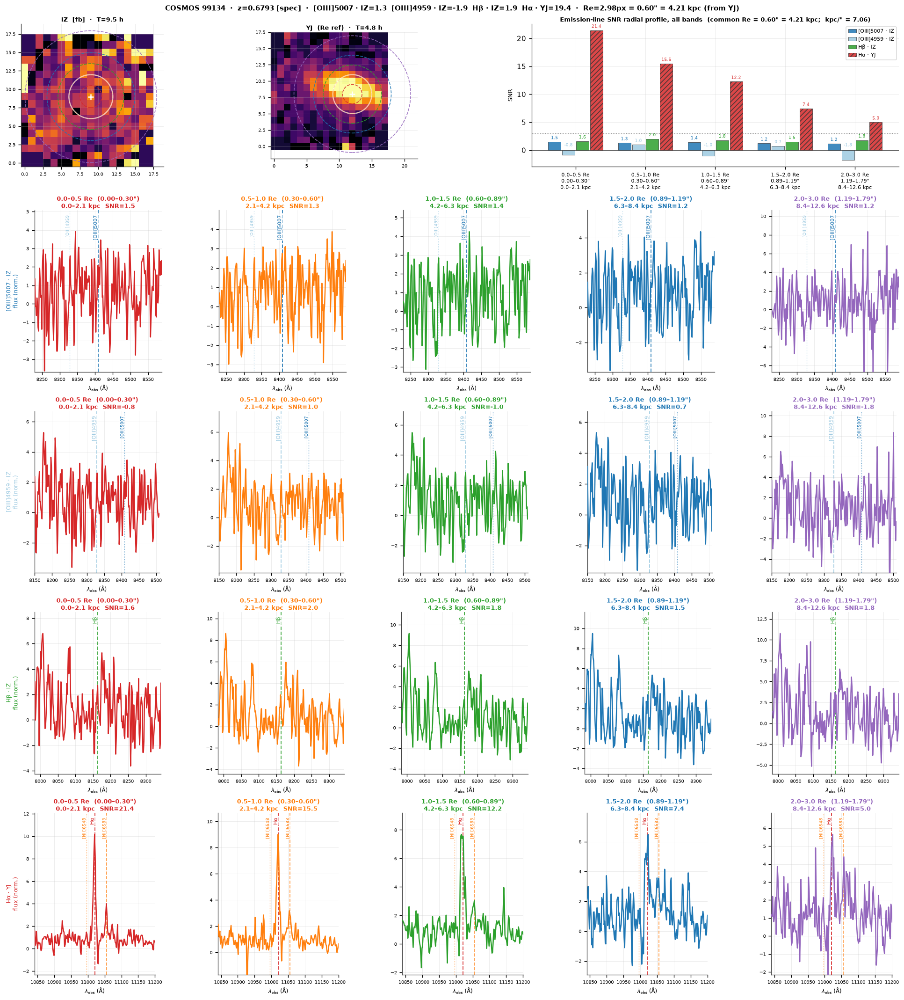

Saved → kmos_snr_reff_group_detail_COSMOS_99134.pdf


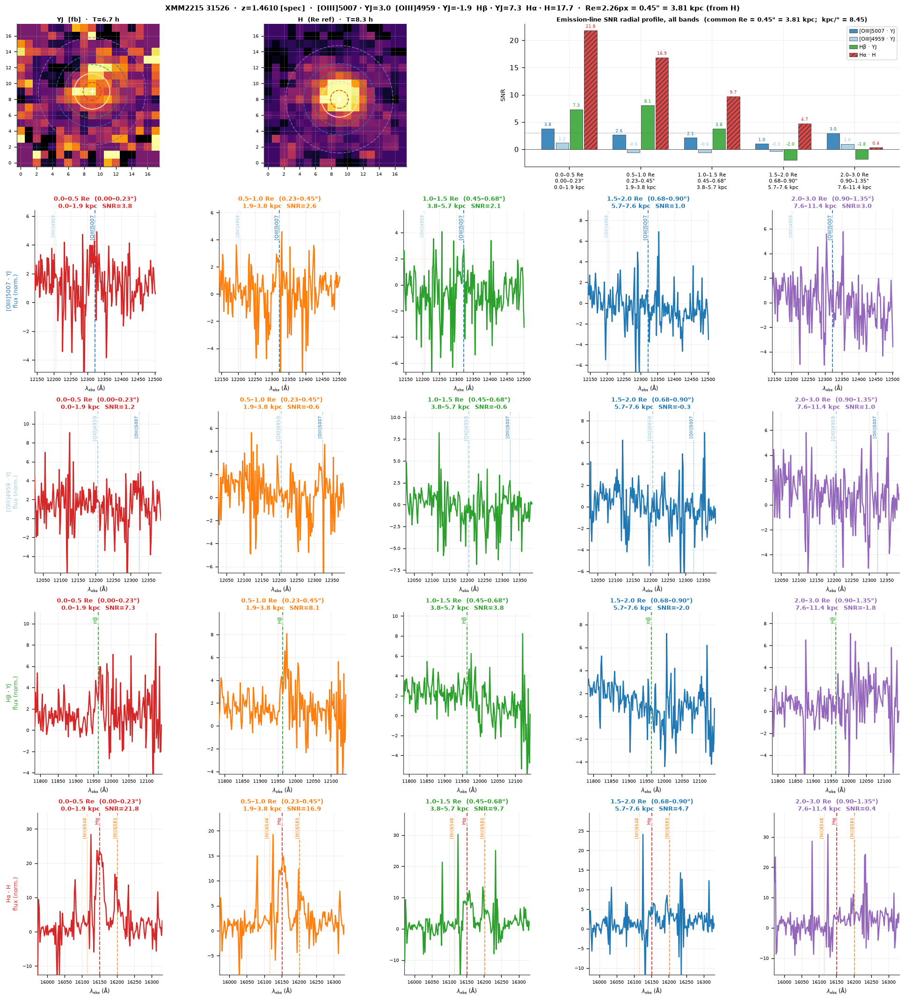

Saved → kmos_snr_reff_group_detail_XMM2215_31526.pdf


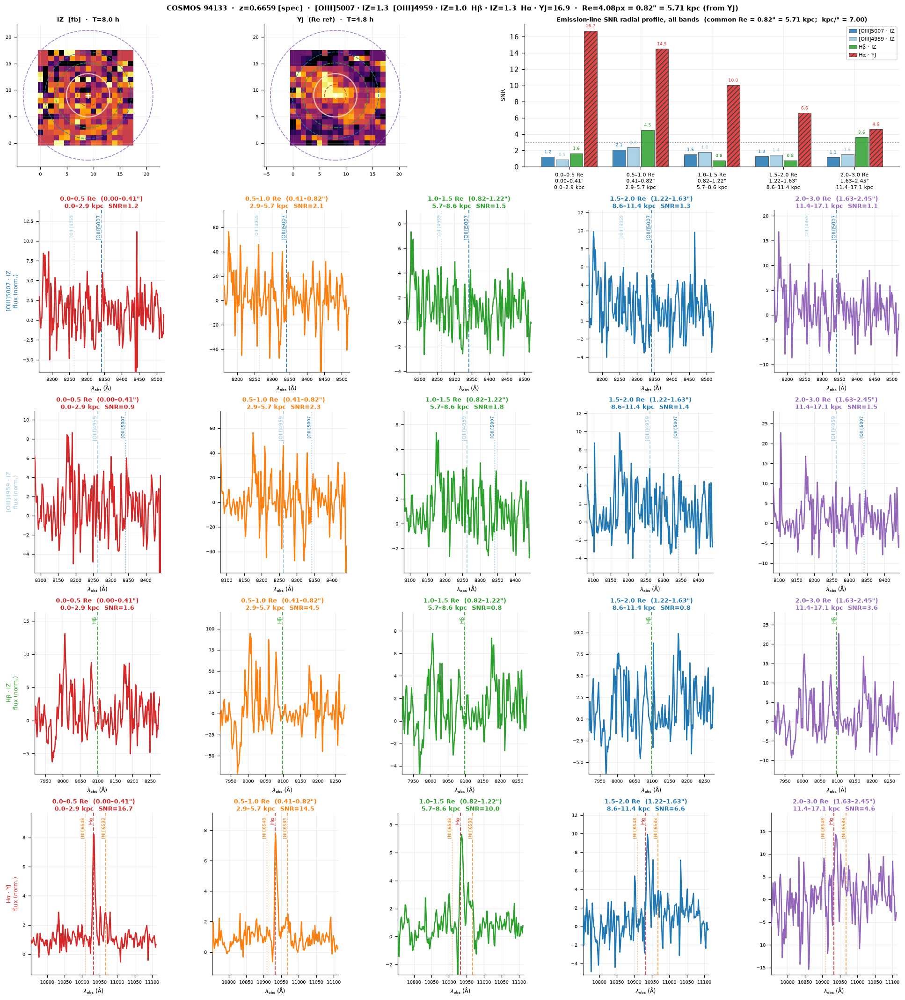

Saved → kmos_snr_reff_group_detail_COSMOS_94133.pdf


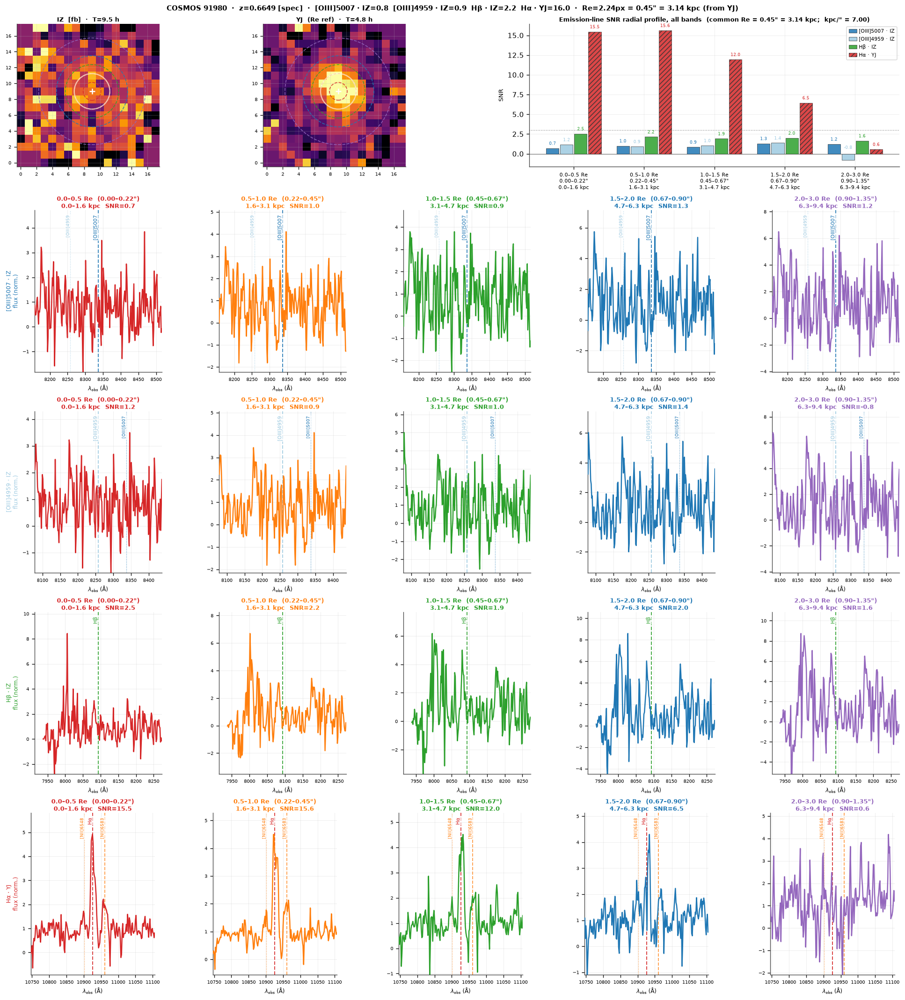

Saved → kmos_snr_reff_group_detail_COSMOS_91980.pdf


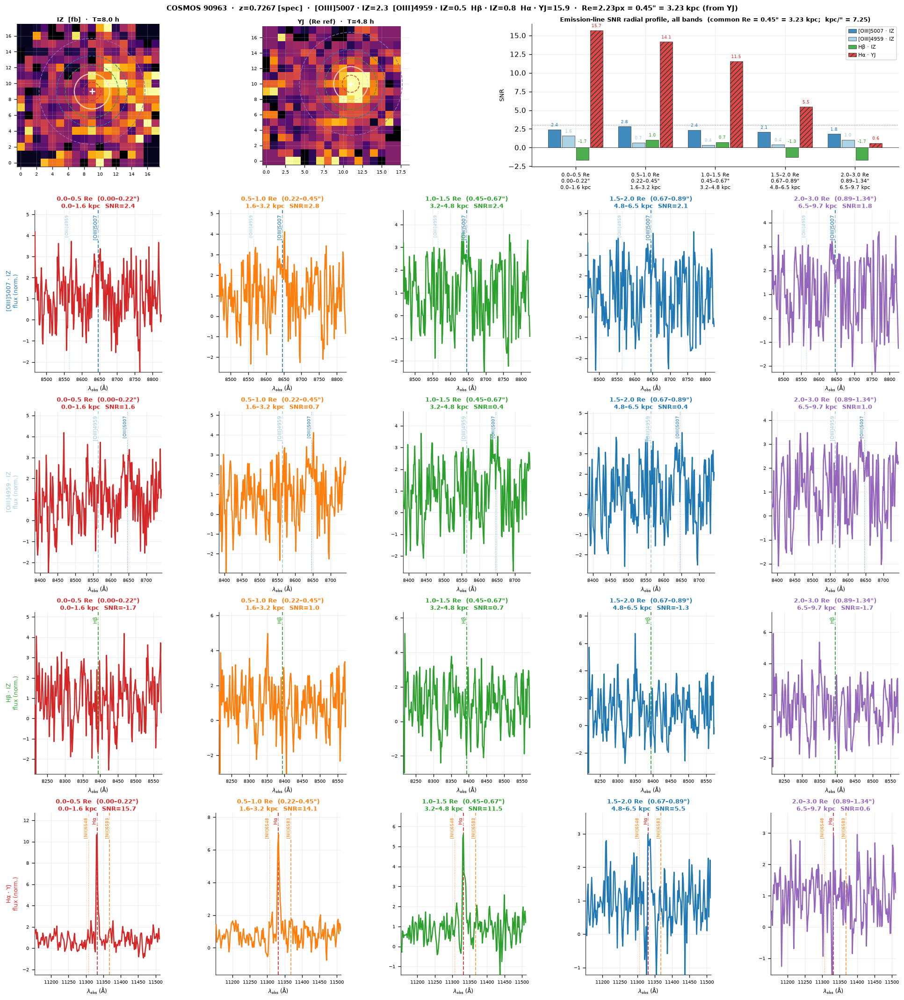

Saved → kmos_snr_reff_group_detail_COSMOS_90963.pdf


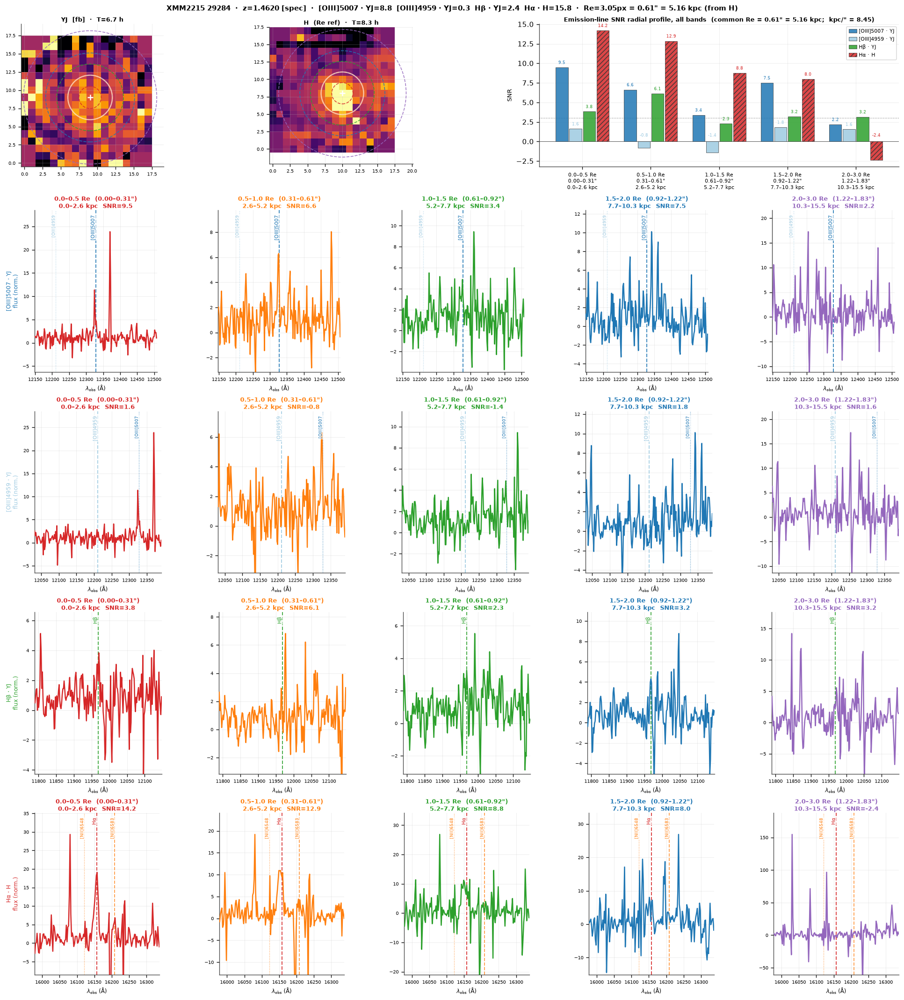

Saved → kmos_snr_reff_group_detail_XMM2215_29284.pdf


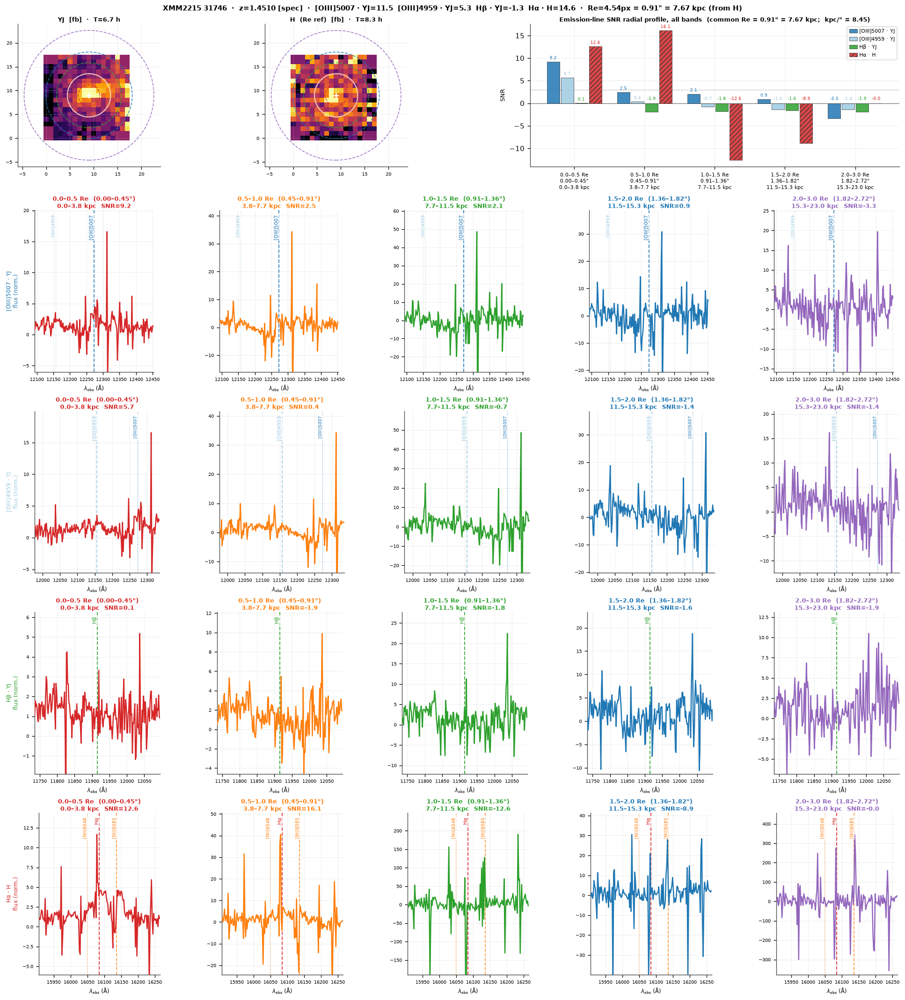

Saved → kmos_snr_reff_group_detail_XMM2215_31746.pdf


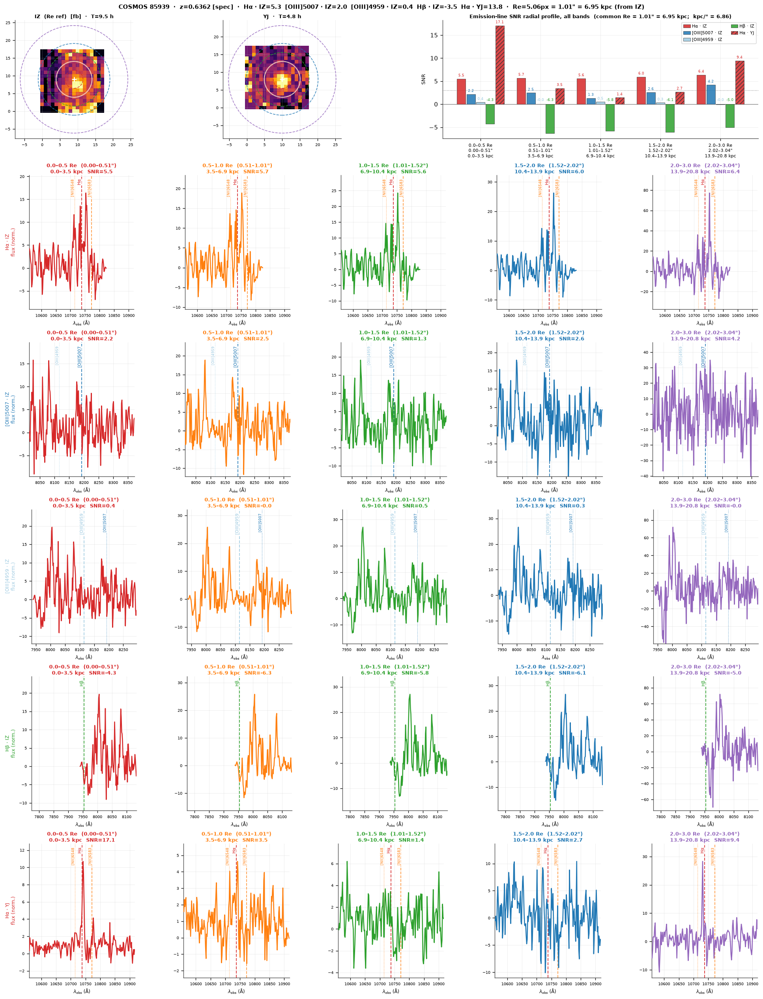

Saved → kmos_snr_reff_group_detail_COSMOS_85939.pdf


In [10]:
LINE_MARKERS = {
    "Hα":          {"[NII]6548": (0.65480, "#ff7f0e", 0.8, ":"),
                    "[NII]6583": (0.65835, "#ff7f0e", 1.1, "--")},
    "[OIII]5007":  {"[OIII]4959": (0.49598, "#9ecae1", 0.8, ":")},
    "[OIII]4959":  {"[OIII]5007": (0.50073, "#1f77b4", 0.8, ":")},
    "Hβ":          {},
}

top_groups = groups[:TOP_DETAIL]

for g in top_groups:
    combos = g['combos']
    nb     = len(g['entries'])
    n_rows = len(combos)
    fig = plt.figure(figsize=(16, 4.5 + n_rows * 3.3), constrained_layout=True)
    snr_parts = [f"{_combo_label(c)}={c['snr_central']:.1f}" if np.isfinite(c['snr_central'])
                 else f"{_combo_label(c)}=—" for c in combos]
    fig.suptitle(
        f"{g['field']} {g['tid']}  ·  z={g['z']:.4f} [{g['z_type']}]  ·  "
        + "  ".join(snr_parts)
        + f"  ·  Re={g['reff_px']:.2f}px = {g['reff_arc']:.2f}\" = {g['reff_kpc']:.2f} kpc "
          f"(from {g['ref']['band']})",
        fontsize=9, fontweight='bold',
    )
    outer = gridspec.GridSpec(1 + n_rows, 1, figure=fig,
                              height_ratios=[1.6] + [1.8] * n_rows, hspace=0.45)

    # ── Row 0: one image per band + joint SNR profile ──────────────────────────
    top_inner = gridspec.GridSpecFromSubplotSpec(
        1, nb + 1, subplot_spec=outer[0], width_ratios=[1] * nb + [2.5], wspace=0.30)
    for bi, e in enumerate(g['entries']):
        _draw_band_image(fig.add_subplot(top_inner[bi]), g, e, title_fs=7.5)
    ax_snr = fig.add_subplot(top_inner[nb])
    _draw_joint_profile(ax_snr, g, annotate=True, tick_fs=6.5)
    ax_snr.set_title(
        f"Emission-line SNR radial profile, all bands  "
        f"(common Re = {g['reff_arc']:.2f}\" = {g['reff_kpc']:.2f} kpc;  "
        f"kpc/\" = {g['kpc_per_arcsec']:.2f})", fontsize=8, pad=3)

    # ── Rows 1+: per (line, band) × per-annulus spectra ────────────────────────
    for row_i, c in enumerate(combos):
        e       = c['entry']
        wave, z = e['wave'], e['z']
        lam_obs = c['lrest'] * (1.0 + z)
        wlo, whi = lam_obs - ZOOM_HALF, lam_obs + ZOOM_HALF
        mask = (wave >= wlo) & (wave <= whi)
        bot_inner = gridspec.GridSpecFromSubplotSpec(
            1, n_ann, subplot_spec=outer[1 + row_i], wspace=0.25)
        companions = LINE_MARKERS.get(c['lbl'], {})

        for ai in range(n_ann):
            ax        = fig.add_subplot(bot_inner[ai])
            spec      = c['specs'][ai]
            snr_v     = c['snrs'][ai]
            ann_color = ANNULUS_COLORS[ai]

            if mask.any() and np.isfinite(spec[mask]).any():
                ax.plot(wave[mask] * 1e4, spec[mask], color=ann_color, lw=1.5, zorder=3)
            else:
                ax.text(0.5, 0.5, 'no signal', ha='center', va='center',
                        transform=ax.transAxes, fontsize=8, color='#aaa', style='italic')

            ax.axvline(lam_obs * 1e4, color=c['lcolor'], lw=1.2, ls='--', alpha=0.85, zorder=2)
            ax.text(lam_obs * 1e4, 0.97, c['lbl'], transform=ax.get_xaxis_transform(),
                    rotation=90, ha='right', va='top', fontsize=6.5, color=c['lcolor'],
                    bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
            for cname, (crest, cc, clw, cls) in companions.items():
                co = crest * (1.0 + z)
                if wlo <= co <= whi:
                    ax.axvline(co * 1e4, color=cc, lw=clw, ls=cls, alpha=0.75, zorder=2)
                    ax.text(co * 1e4, 0.97, cname, transform=ax.get_xaxis_transform(),
                            rotation=90, ha='right', va='top', fontsize=5.5, color=cc,
                            bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))

            vis = spec[mask] if mask.any() else np.array([])
            fv  = vis[np.isfinite(vis)]
            if fv.size:
                ylo_, yhi_ = np.nanpercentile(fv, 2), np.nanmax(fv)
                pad = 0.18 * max(yhi_ - ylo_, 1e-6)
                ax.set_ylim(ylo_ - pad, yhi_ + pad)
            ax.set_xlim(wlo * 1e4, whi * 1e4)
            ax.tick_params(labelsize=6)
            ax.set_xlabel(r"$\lambda_{\rm obs}$ (Å)", fontsize=7)
            snr_s = f"SNR={snr_v:.1f}" if np.isfinite(snr_v) else "SNR=—"
            ax.set_title(
                f"{REFF_EDGES[ai]:.1f}–{REFF_EDGES[ai+1]:.1f} Re  "
                f"({g['edges_arc'][ai]:.2f}–{g['edges_arc'][ai+1]:.2f}\")\n"
                f"{g['edges_kpc'][ai]:.1f}–{g['edges_kpc'][ai+1]:.1f} kpc  {snr_s}",
                fontsize=7.5, color=ann_color, pad=3)
            if ai == 0:
                ax.set_ylabel(f"{_combo_label(c)}\nflux (norm.)", fontsize=7, color=c['lcolor'])

    fname = f"kmos_snr_reff_group_detail_{g['field']}_{g['tid']}.pdf"
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")